In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()


(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(len(missing), "columns have missing values")
print(missing.head(10))

19 columns have missing values
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64


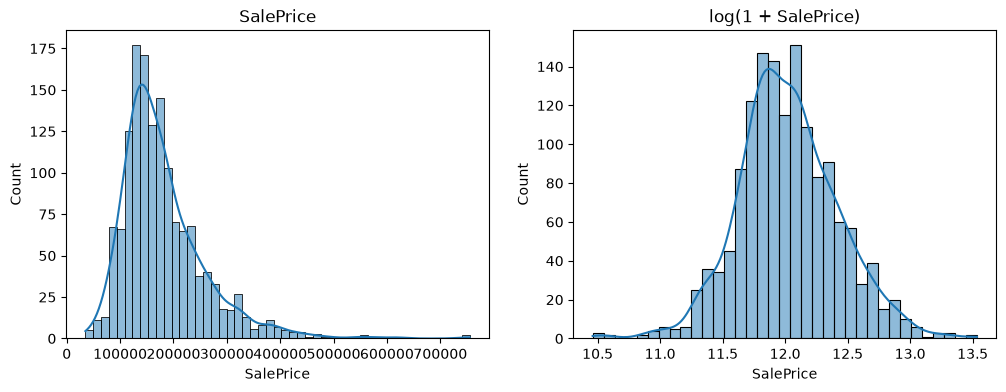

Skew: 1.8828757597682129
Skew after log: 0.12134661989685333


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=ax[1])
ax[0].set_title("SalePrice")
ax[1].set_title("log(1 + SalePrice)")
plt.show()

print("Skew:", df["SalePrice"].skew())
print("Skew after log:", np.log1p(df["SalePrice"]).skew())

In [4]:
has_pool = df["PoolArea"] > 0

print("Houses with a pool:", has_pool.sum())
print("PoolQC missing:", df["PoolQC"].isna().sum())
print("Has pool BUT PoolQC missing:", (has_pool & df["PoolQC"].isna()).sum())
print("No pool BUT PoolQC filled:", (~has_pool & df["PoolQC"].notna()).sum())

Houses with a pool: 7
PoolQC missing: 1453
Has pool BUT PoolQC missing: 0
No pool BUT PoolQC filled: 0


In [5]:
has_pool = df["PoolArea"] > 0

print("Houses with a pool:", has_pool.sum())
print("PoolQC missing:", df["PoolQC"].isna().sum())
print("Has pool BUT PoolQC missing:", (has_pool & df["PoolQC"].isna()).sum())
print("No pool BUT PoolQC filled:", (~has_pool & df["PoolQC"].notna()).sum())

Houses with a pool: 7
PoolQC missing: 1453
Has pool BUT PoolQC missing: 0
No pool BUT PoolQC filled: 0


In [6]:
print(df.dtypes.value_counts())
print()
print(df.select_dtypes(include="number").columns.tolist())
print()
print(df.select_dtypes(include="object").columns.tolist())

str        43
int64      35
float64     3
Name: count, dtype: int64

['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQ

C:\Users\USER\AppData\Local\Temp\ipykernel_28408\2682839181.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [7]:
no_garage = df["GarageArea"] == 0

print("Houses with no garage:", no_garage.sum())
for col in ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]:
    print(col, "| missing:", df[col].isna().sum(),
          "| missing but has garage:", (df[col].isna() & ~no_garage).sum(),
          "| filled but no garage:", (df[col].notna() & no_garage).sum())

Houses with no garage: 81
GarageType | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageFinish | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageQual | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageCond | missing: 81 | missing but has garage: 0 | filled but no garage: 0


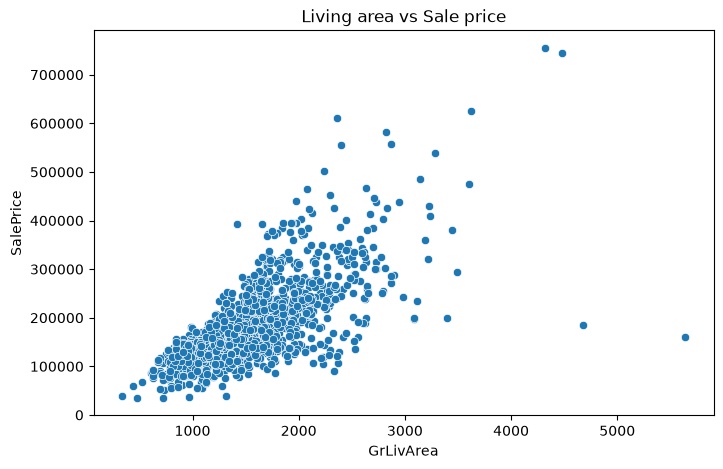

        Id  GrLivArea  SalePrice Neighborhood SaleCondition
523    524       4676     184750      Edwards       Partial
691    692       4316     755000      NoRidge        Normal
1182  1183       4476     745000      NoRidge       Abnorml
1298  1299       5642     160000      Edwards       Partial


In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)
plt.title("Living area vs Sale price")
plt.show()

print(df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "Neighborhood", "SaleCondition"]])

In [9]:
df_clean = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].copy()
print(df.shape, "->", df_clean.shape)
print("Removed Ids:", sorted(set(df["Id"]) - set(df_clean["Id"])))

(1460, 81) -> (1458, 81)
Removed Ids: [524, 1299]


OverallQual     0.795774
GrLivArea       0.734968
TotalBsmtSF     0.651153
GarageCars      0.641047
1stFlrSF        0.631530
GarageArea      0.629217
FullBath        0.562165
TotRmsAbvGrd    0.537769
YearBuilt       0.523608
YearRemodAdd    0.507717
Name: SalePrice, dtype: float64

YrSold          -0.028882
OverallCond     -0.077948
MSSubClass      -0.084276
EnclosedPorch   -0.128646
KitchenAbvGr    -0.135946
Name: SalePrice, dtype: float64


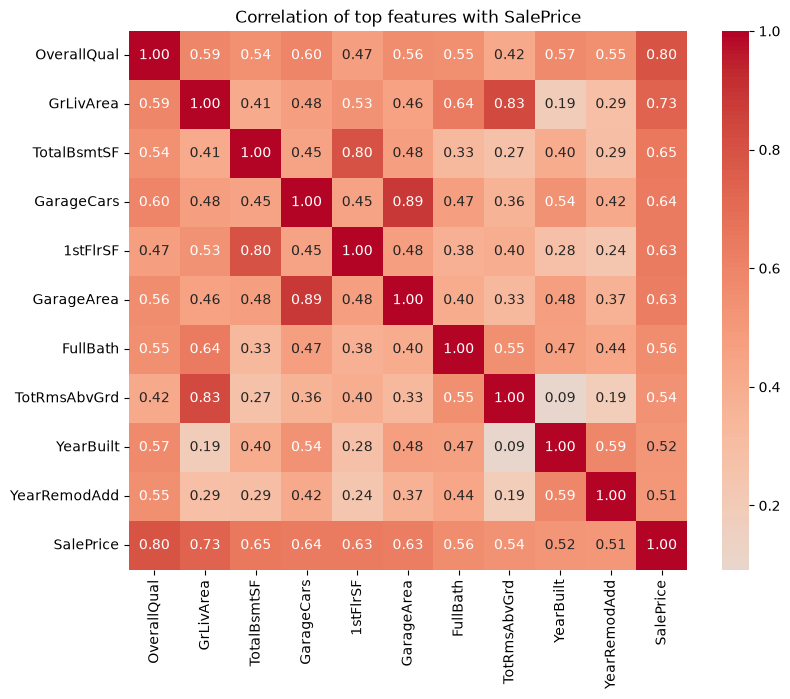

In [10]:
num = df_clean.select_dtypes(include="number").drop(columns="Id")
corr = num.corr()

top = corr["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print(top.head(10))
print()
print(top.tail(5))

top_cols = top.abs().sort_values(ascending=False).head(10).index.tolist() + ["SalePrice"]
plt.figure(figsize=(9, 7))
sns.heatmap(num[top_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of top features with SalePrice")
plt.show()

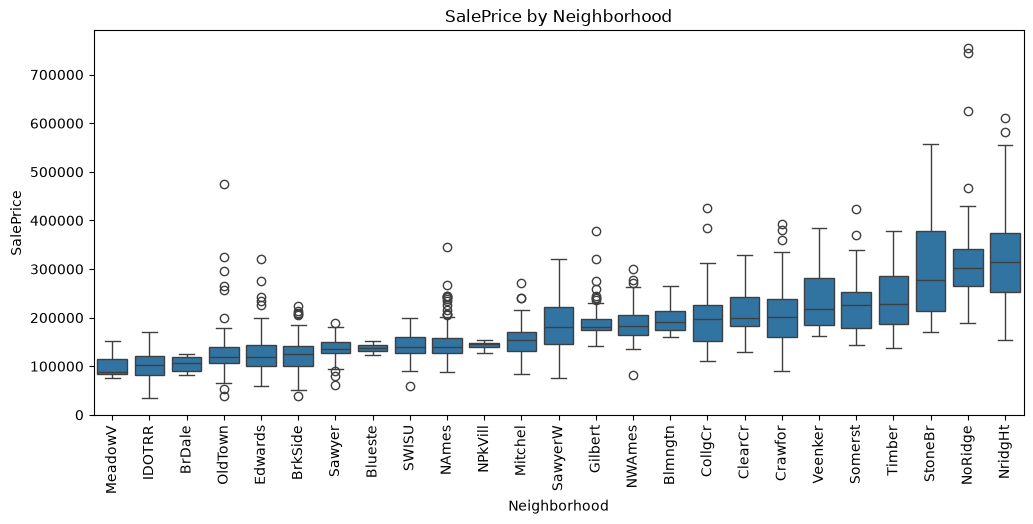

25 neighborhoods
Neighborhood
MeadowV     88000.0
IDOTRR     103000.0
BrDale     106000.0
OldTown    119000.0
Edwards    119500.0
BrkSide    124300.0
Sawyer     135000.0
Blueste    137500.0
SWISU      139500.0
NAmes      140000.0
NPkVill    146000.0
Mitchel    153500.0
SawyerW    179900.0
Gilbert    181000.0
NWAmes     182900.0
Blmngtn    191000.0
CollgCr    197200.0
ClearCr    200250.0
Crawfor    200624.0
Veenker    218000.0
Somerst    225500.0
Timber     228475.0
StoneBr    278000.0
NoRidge    301500.0
NridgHt    315000.0
Name: SalePrice, dtype: float64


In [11]:
order = df_clean.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df_clean, order=order)
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood")
plt.show()

print(df_clean["Neighborhood"].nunique(), "neighborhoods")
print(df_clean.groupby("Neighborhood")["SalePrice"].median().sort_values())

In [12]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]

df_clean[none_cols] = df_clean[none_cols].fillna("None")
df_clean["MSSubClass"] = df_clean["MSSubClass"].astype(str)

remaining = df_clean.isna().sum()
print(remaining[remaining > 0])

LotFrontage    259
MasVnrArea       8
Electrical       1
GarageYrBlt     81
dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Id", "SalePrice"])
y = np.log1p(df_clean["SalePrice"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1166, 79) | Test: (292, 79)


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

baseline = Pipeline([("prep", preprocess), ("model", LinearRegression())])
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, pred))
print("Test RMSE (log scale):", rmse)

Test RMSE (log scale): 0.1406974021195518


In [15]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(model):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=kf,
                             scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std()

models = {
    "LinearRegression": LinearRegression(),
    "Ridge(alpha=10)": Ridge(alpha=10),
    "Lasso(alpha=0.001)": Lasso(alpha=0.001, max_iter=20000),
}

for name, m in models.items():
    mean, std = cv_rmse(m)
    print(f"{name:22s} CV RMSE: {mean:.4f} (+/- {std:.4f})")

LinearRegression       CV RMSE: 0.1302 (+/- 0.0120)
Ridge(alpha=10)        CV RMSE: 0.1118 (+/- 0.0100)
Lasso(alpha=0.001)     CV RMSE: 0.1128 (+/- 0.0087)


In [17]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models2 = {
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                             random_state=42, n_jobs=-1),
}

for name, m in models2.items():
    mean, std = cv_rmse(m)
    print(f"{name:22s} CV RMSE: {mean:.4f} (+/- {std:.4f})")

RandomForest           CV RMSE: 0.1394 (+/- 0.0108)
XGBoost                CV RMSE: 0.1199 (+/- 0.0101)
